# Лабораторная работа №2
## «Виртуальный датчик для контроля процесса обжига в печи»

Исходные данные: data_train.csv — минутные измерения 16 показателей телеметрии за 8 месяцев для обучения; target_train.csv — лабораторные замеры концентрации целевого продукта (нерегулярные, с задержкой 10-15 мин);
data_test_small.csv, target_test_small.csv — аналогичные данные для тестирования



## 2.1 Разведочный анализ данных (EDA)

In [ ]:
# Загрузка библиотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Настройки отображения
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

print("Библиотеки успешно импортированы")

Библиотеки успешно импортированы


In [ ]:
# Загрузка данных
DATA_DIR = Path("/content")

def load_data(filename):
    df = pd.read_csv(DATA_DIR / filename)

    # Приводим названия временных столбцов к одному виду
    df = df.rename(columns={"Дата": "datetime"})

    # Преобразуем даты и сортируем по времени
    df["datetime"] = pd.to_datetime(df["datetime"])
    df = df.sort_values("datetime").reset_index(drop=True)

    return df


# Обучающие данные
data_train = load_data("data_train.csv")
target_train = load_data("target_train.csv")

# Тестовые данные
data_test = load_data("data_test_small.csv")
target_test = load_data("target_test_small.csv")

print("Все файлы успешно загружены!")

Все файлы успешно загружены!


### 2.1.1. Первичное исследование структуры данных

На первом этапе проведем изучение структуры исходных наборов данных: количества наблюдений и признаков, типов данных, временных диапазонов и наличия повторяющихся временных меток.

Основная задача — определить особенности телеметрических и лабораторных измерений, которые необходимо учитывать при дальнейшей обработке.

Тестовая выборка используется только для итоговой оценки моделей, чтобы избежать утечки информации и получить объективные показатели качества.

In [ ]:
datasets = {
    "Обучающая телеметрия": data_train,
    "Обучающие лабораторные замеры": target_train,
    "Тестовая телеметрия": data_test,
    "Тестовые лабораторные замеры": target_test
}

# Сравниваем размеры наборов данных
for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} строк, {df.shape[1]} столбцов")

print("\nПервые строки телеметрии:")
display(data_train.head())

print("\nПервые строки целевой переменной:")
display(target_train.head())

print("\nТипы данных:")
display(data_train.dtypes)

Обучающая телеметрия: 319546 строк, 17 столбцов
Обучающие лабораторные замеры: 1773 строк, 2 столбцов
Тестовая телеметрия: 39943 строк, 17 столбцов
Тестовые лабораторные замеры: 318 строк, 2 столбцов

Первые строки телеметрии:


,datetime,telemetry_0,telemetry_1,telemetry_2,telemetry_3,telemetry_4,telemetry_5,telemetry_6,telemetry_7,telemetry_8,telemetry_9,telemetry_10,telemetry_11,telemetry_12,telemetry_13,telemetry_14,telemetry_15
0,2019-03-01 00:01:00,0.7375,0.4784,0.2928,0.6440,0.9195,0.8848,0.7548,0.4133,0.4719,0.6778,0.6875,0.4984,NaN,NaN,NaN,NaN
1,2019-03-01 00:02:00,0.7384,0.4790,0.2928,0.6486,0.9195,0.8871,0.7530,0.4133,0.4719,0.6778,0.6889,0.4984,NaN,NaN,NaN,NaN
2,2019-03-01 00:03:00,0.7390,0.4790,0.2928,0.6472,0.9195,0.8871,0.7554,0.4133,0.4719,0.6778,0.6903,0.4984,NaN,NaN,NaN,NaN
3,2019-03-01 00:04:00,0.7396,0.4790,0.2928,0.6369,0.9195,0.8871,0.7548,0.4133,0.4719,0.6781,0.6928,0.4984,NaN,NaN,NaN,NaN
4,2019-03-01 00:05:00,0.7404,0.4771,0.2928,0.6358,0.9195,0.8877,0.7542,0.4133,0.4719,0.6784,0.6956,0.4984,NaN,NaN,NaN,NaN



Первые строки целевой переменной:


,datetime,target
0,2019-03-13 17:00:00,0.1237
1,2019-03-13 21:00:00,0.3196
2,2019-03-14 01:00:00,0.2552
3,2019-03-14 05:00:00,0.3196
4,2019-03-14 09:00:00,0.1598



Типы данных:


,0
datetime,datetime64[ns]
telemetry_0,float64
telemetry_1,float64
telemetry_2,float64
telemetry_3,float64
telemetry_4,float64
telemetry_5,float64
telemetry_6,float64
telemetry_7,float64
telemetry_8,float64


In [ ]:
for name, df in datasets.items():
    print(f"\n{name}")
    print("Начало:", df["datetime"].min())
    print("Конец:", df["datetime"].max())

    # Проверяем повторяющиеся временные метки
    duplicates = df["datetime"].duplicated().sum()
    print("Дубликаты времени:", duplicates)


Обучающая телеметрия
Начало: 2019-03-01 00:01:00
Конец: 2019-10-07 19:58:00
Дубликаты времени: 1548

Обучающие лабораторные замеры
Начало: 2019-03-13 17:00:00
Конец: 2019-10-07 21:00:00
Дубликаты времени: 0

Тестовая телеметрия
Начало: 2019-10-07 19:59:00
Конец: 2019-11-04 10:25:00
Дубликаты времени: 196

Тестовые лабораторные замеры
Начало: 2019-10-07 23:00:00
Конец: 2019-11-04 09:00:00
Дубликаты времени: 0


### 2.1.2. Анализ пропущенных значений

Пропуски в показаниях промышленных датчиков могут быть связаны с временной недоступностью оборудования, сбоями передачи данных или различной периодичностью измерений.

Необходимо определить долю пропущенных значений для каждого признака и выяснить, имеют ли пропуски случайный или закономерный характер.

,"Train, %","Test, %"
telemetry_0,0.0100,0.0000
telemetry_1,0.0100,0.0000
telemetry_2,0.0100,0.0000
telemetry_3,0.0100,0.0000
telemetry_4,0.0400,0.0000
telemetry_5,0.0100,0.0000
telemetry_6,0.0100,0.0000
telemetry_7,0.0100,0.0000
telemetry_8,0.0100,0.0000
telemetry_9,0.0100,0.0000


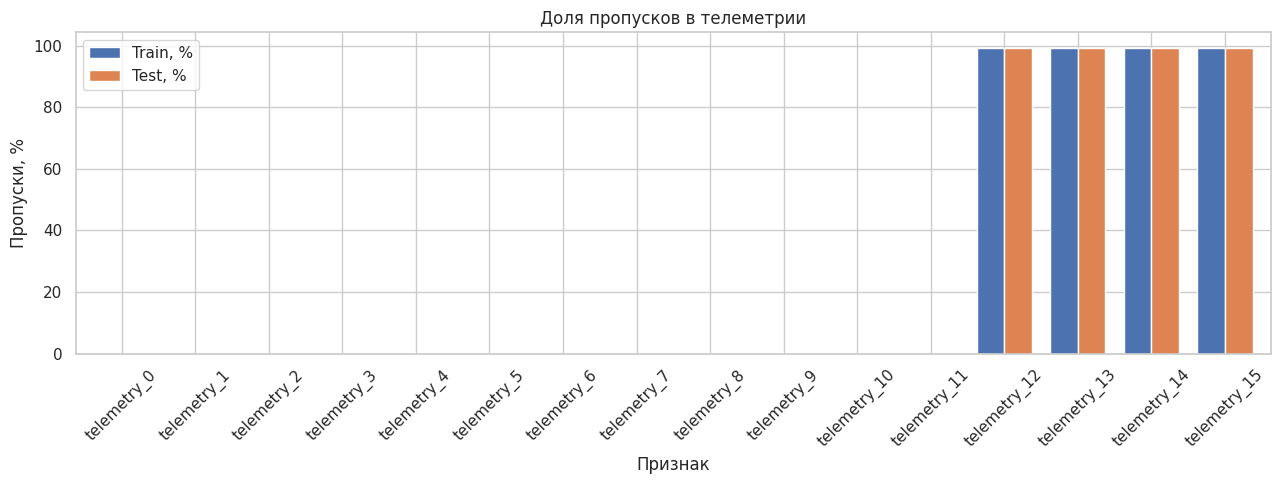

In [6]:
telemetry_cols = [col for col in data_train.columns
                  if col.startswith("telemetry_")]

# Доля пропусков по каждому признаку
missing_summary = pd.DataFrame({
    "Train, %": data_train[telemetry_cols].isna().mean() * 100,
    "Test, %": data_test[telemetry_cols].isna().mean() * 100
})

display(missing_summary.round(2))

# Визуализация
missing_summary.plot(
    kind="bar", figsize=(13, 5), width=0.75
)

plt.title("Доля пропусков в телеметрии")
plt.ylabel("Пропуски, %")
plt.xlabel("Признак")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [7]:
sparse_cols = telemetry_cols[12:]

for col in sparse_cols:
    # Временные метки доступных измерений
    times = (
        data_train.loc[data_train[col].notna(), "datetime"]
        .drop_duplicates()
        .sort_values()
    )

    intervals = times.diff().dropna()

    print(f"\n{col}")
    print("Количество измерений:", len(times))
    print("Наиболее частые интервалы:")
    print(intervals.value_counts().head(3))


telemetry_12
Количество измерений: 2097
Наиболее частые интервалы:
datetime
0 days 02:00:00    2071
0 days 04:00:00      11
0 days 06:00:00       2
Name: count, dtype: int64

telemetry_13
Количество измерений: 2097
Наиболее частые интервалы:
datetime
0 days 02:00:00    2071
0 days 04:00:00      11
0 days 06:00:00       2
Name: count, dtype: int64

telemetry_14
Количество измерений: 2097
Наиболее частые интервалы:
datetime
0 days 02:00:00    2071
0 days 04:00:00      11
0 days 06:00:00       2
Name: count, dtype: int64

telemetry_15
Количество измерений: 2097
Наиболее частые интервалы:
datetime
0 days 02:00:00    2071
0 days 04:00:00      11
0 days 06:00:00       2
Name: count, dtype: int64


In [8]:
def clean_duplicates(df):
    # Усредняем повторяющиеся измерения
    return (
        df.groupby("datetime", as_index=False)[telemetry_cols]
        .mean()
        .sort_values("datetime")
        .reset_index(drop=True)
    )


data_train_clean = clean_duplicates(data_train)
data_test_clean = clean_duplicates(data_test)

print("Train:", data_train.shape, "→", data_train_clean.shape)
print("Test:", data_test.shape, "→", data_test_clean.shape)

# Проверяем непрерывность временной шкалы
for name, df in {
    "Train": data_train_clean,
    "Test": data_test_clean
}.items():
    gaps = (df["datetime"].diff().dropna()
            != pd.Timedelta(minutes=1)).sum()

    print(f"{name}: нарушений минутного интервала — {gaps}")

Train: (319546, 17) → (317998, 17)
Test: (39943, 17) → (39747, 17)
Train: нарушений минутного интервала — 0
Test: нарушений минутного интервала — 0


In [9]:
# Признаки с долей пропусков менее 5%
dense_cols = missing_summary.index[
    missing_summary["Train, %"] < 5
].tolist()

stats = data_train_clean[dense_cols].describe(
    percentiles=[0.01, 0.5, 0.99]
).T

display(stats.round(4))

,count,mean,std,min,1%,50%,99%,max
telemetry_0,317981.0000,0.6100,0.2763,0.0035,0.0055,0.7390,0.8252,1.0000
telemetry_1,317982.0000,0.3800,0.1978,0.0000,0.0000,0.4861,0.5178,0.6108
telemetry_2,317982.0000,0.2668,0.0881,0.0318,0.0382,0.2957,0.4366,1.0000
telemetry_3,317982.0000,0.5201,0.2593,0.0000,0.0000,0.6395,0.7100,1.0000
telemetry_4,317865.0000,0.7620,0.3257,0.0000,0.0000,0.9195,0.9197,1.0000
telemetry_5,317981.0000,0.6959,0.2842,0.0000,0.0391,0.8295,0.9135,1.0000
telemetry_6,317982.0000,0.5940,0.3004,0.0000,0.0000,0.7492,0.7858,1.0000
telemetry_7,317982.0000,0.5227,0.2529,0.0206,0.2766,0.4108,1.0000,1.0000
telemetry_8,317982.0000,0.4696,0.0238,0.3440,0.4149,0.4679,0.5205,1.0000
telemetry_9,317982.0000,0.5358,0.2548,0.0000,0.0381,0.5818,1.0000,1.0000


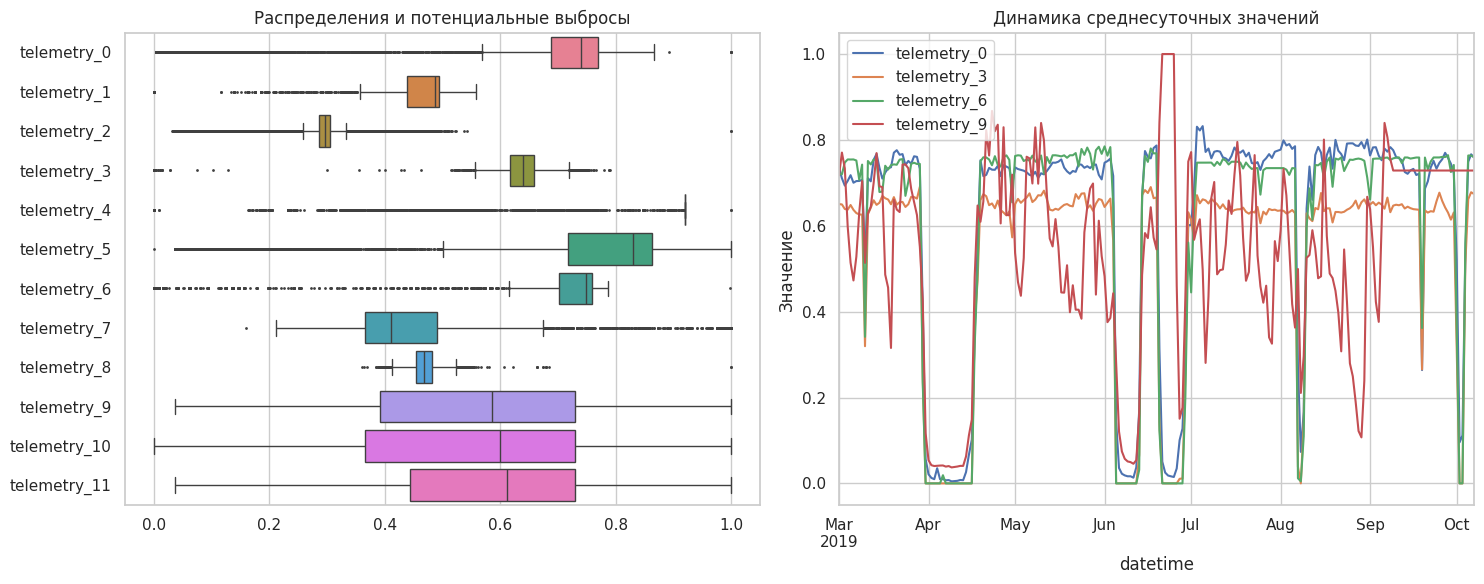

In [10]:
# Выборка для ускорения визуализации
sample = data_train_clean[dense_cols].sample(
    n=min(20000, len(data_train_clean)),
    random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Распределения
sample.hist(
    column=dense_cols[:4],
    ax=axes[0] if False else None
) if False else None

# Диаграмма размаха
sns.boxplot(
    data=sample,
    orient="h",
    ax=axes[0],
    fliersize=1
)
axes[0].set_title("Распределения и потенциальные выбросы")

# Динамика отдельных признаков
plot_cols = ["telemetry_0", "telemetry_3",
             "telemetry_6", "telemetry_9"]

daily = (
    data_train_clean
    .set_index("datetime")[plot_cols]
    .resample("D")
    .mean()
)

daily.plot(ax=axes[1])
axes[1].set_title("Динамика среднесуточных значений")
axes[1].set_ylabel("Значение")

plt.tight_layout()
plt.show()

В ходе первичного анализа установлено:

Телеметрические данные содержат 16 числовых признаков и временную метку. Первые 12 признаков имеют крайне малую долю пропусков.

Признаки telemetry_12–telemetry_15 содержат около 99% пропущенных значений. Их периодичность необходимо учитывать при выборе способа заполнения.

Обнаружены повторяющиеся временные метки: 1548 в обучающем наборе и 196 в тестовом. Для устранения повторений использовано усреднение значений по времени.

При анализе аномальных значений необходимо учитывать, что резкие изменения телеметрии могут быть связаны с реальными переходами между режимами работы оборудования.

Таким образом, предварительная обработка должна сохранять временной порядок наблюдений и не приводить к потере информации о динамике процесса.

### 2.1.3. Исследование целевой переменной

Целевая переменная `target` представляет собой концентрацию выходного продукта, измеренную лабораторным способом.

Для оценки возможности прогнозирования необходимо исследовать распределение целевой переменной, её изменение во времени и частоту проведения лабораторных измерений.

Особое внимание уделить длительным промежуткам между измерениями, поскольку они ограничивают количество доступных обучающих примеров.

Для анализа используется обучающая выборка. Тестовые значения сохраняются для последующей оценки качества моделей.

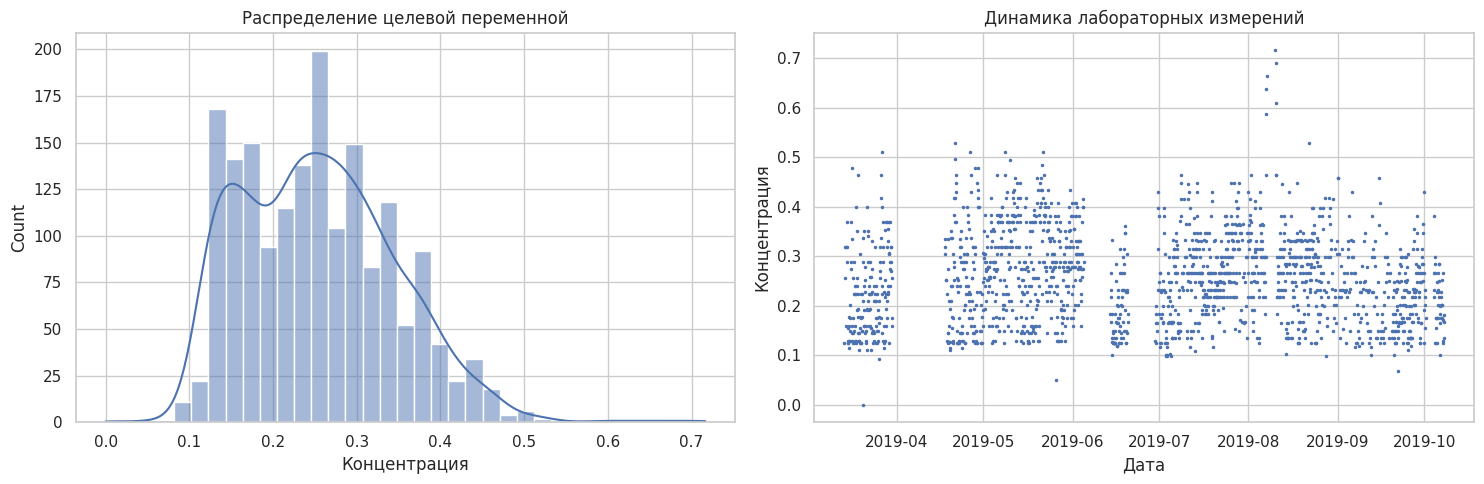

,target
count,1773.0000
mean,0.2543
std,0.0922
min,0.0000
25%,0.1753
50%,0.2474
75%,0.3144
max,0.7165


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Распределение концентрации
sns.histplot(
    target_train["target"],
    bins=35,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Распределение целевой переменной")
axes[0].set_xlabel("Концентрация")

# Изменение концентрации во времени
axes[1].plot(
    target_train["datetime"],
    target_train["target"],
    marker=".",
    linestyle="none",
    markersize=3
)
axes[1].set_title("Динамика лабораторных измерений")
axes[1].set_xlabel("Дата")
axes[1].set_ylabel("Концентрация")

plt.tight_layout()
plt.show()

display(target_train["target"].describe().round(4))

Наиболее частые интервалы (часы):


,count
datetime,
2.0000,1570
4.0000,184
1.0000,4
7.0000,2
440.5000,1
11.0000,1
14.0000,1
1.5000,1
222.0000,1


Медианный интервал: 2.0 ч
Максимальный интервал: 440.5 ч
Интервалов больше 4 часов: 13


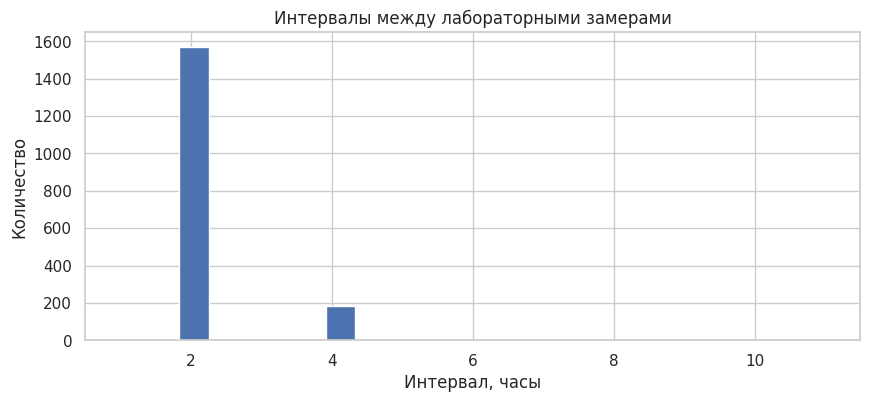

In [12]:
# Интервалы между последовательными замерами в часах
target_intervals = (
    target_train["datetime"]
    .diff()
    .dt.total_seconds() / 3600
).dropna()

print("Наиболее частые интервалы (часы):")
display(target_intervals.value_counts().head(10))

print("Медианный интервал:", target_intervals.median(), "ч")
print("Максимальный интервал:", target_intervals.max(), "ч")
print("Интервалов больше 4 часов:", (target_intervals > 4).sum())

# Распределение основных интервалов
target_intervals[target_intervals <= 12].hist(
    bins=24,
    figsize=(10, 4)
)

plt.title("Интервалы между лабораторными замерами")
plt.xlabel("Интервал, часы")
plt.ylabel("Количество")
plt.show()

### 2.1.4. Синхронизация временных рядов

Телеметрия поступает с минутной периодичностью, тогда как лабораторные замеры выполняются преимущественно каждые 2–4 часа.

Дополнительной особенностью является задержка получения лабораторного результата на 10–15 минут после отбора пробы.

Для сопоставления данных используется временное объединение `merge_asof`, позволяющее подобрать последнюю доступную запись телеметрии, не превышающую заданный момент времени.

**Рабочее предположение:** временная метка лабораторного результата соответствует моменту получения результата. Тогда время отбора пробы можно приблизительно восстановить, вычитая 15 минут.

Если временная метка в исходном файле уже обозначает момент отбора пробы, сдвиг не требуется. Поскольку точное значение поля в задании не указано, выбранное предположение необходимо проверить при дальнейшем моделировании.

Такой подход позволяет избежать использования будущих значений телеметрии при прогнозировании концентрации.

In [13]:
# Предполагаемая задержка лабораторного результата
LAB_DELAY = 15

lab = target_train.rename(
    columns={"datetime": "lab_time"}
).copy()

# Восстанавливаем предполагаемое время отбора пробы
lab["sample_time"] = (
    lab["lab_time"] - pd.Timedelta(minutes=LAB_DELAY)
)

lab = lab.sort_values("sample_time")

# Сопоставляем замер с предыдущей записью телеметрии
train_aligned = pd.merge_asof(
    lab,
    data_train_clean,
    left_on="sample_time",
    right_on="datetime",
    direction="backward",
    tolerance=pd.Timedelta(minutes=1)
)

# Удаляем записи, для которых телеметрия отсутствует
unmatched = train_aligned["datetime"].isna().sum()
train_aligned = train_aligned.dropna(
    subset=["datetime"]
).reset_index(drop=True)

print("Совмещено измерений:", len(train_aligned))
print("Без соответствующей телеметрии:", unmatched)

display(
    train_aligned[
        ["lab_time", "sample_time", "datetime",
         "target", "telemetry_0", "telemetry_1"]
    ].head()
)

Совмещено измерений: 1772
Без соответствующей телеметрии: 1


,lab_time,sample_time,datetime,target,telemetry_0,telemetry_1
0,2019-03-13 17:00:00,2019-03-13 16:45:00,2019-03-13 16:45:00,0.1237,0.7870,0.4976
1,2019-03-13 21:00:00,2019-03-13 20:45:00,2019-03-13 20:45:00,0.3196,0.7824,0.4976
2,2019-03-14 01:00:00,2019-03-14 00:45:00,2019-03-14 00:45:00,0.2552,0.7885,0.4975
3,2019-03-14 05:00:00,2019-03-14 04:45:00,2019-03-14 04:45:00,0.3196,0.7500,0.4898
4,2019-03-14 09:00:00,2019-03-14 08:45:00,2019-03-14 08:45:00,0.1598,0.7697,0.4930


In [14]:
# Разница между временем отбора и телеметрией
time_diff = (
    train_aligned["sample_time"] -
    train_aligned["datetime"]
).dt.total_seconds() / 60

print("Максимальное расхождение, мин:", time_diff.max())
print("Минимальное расхождение, мин:", time_diff.min())

# Проверяем отсутствие будущих измерений
assert (time_diff >= 0).all()
assert (time_diff <= 1).all()

print("Синхронизация выполнена корректно")

Максимальное расхождение, мин: 0.0
Минимальное расхождение, мин: 0.0
Синхронизация выполнена корректно


Лабораторные измерения характеризуются значительно меньшей частотой по сравнению с телеметрией. Основные интервалы между измерениями составляют 2 и 4 часа, однако встречаются и продолжительные периоды отсутствия наблюдений.

Для синхронизации временных рядов использовано объединение по ближайшему предшествующему моменту времени. В качестве рабочего предположения принята задержка получения лабораторного результата 15 минут.

После синхронизации получено 1772 наблюдения, которые могут использоваться при построении прогнозных моделей.

В дальнейшем необходимо исследовать влияние предполагаемой задержки на качество прогнозирования и оценить взаимосвязи между целевой переменной и показателями телеметрии с учётом временных лагов.

### 2.1.5. Анализ сезонности

Для выявления возможных периодических закономерностей исследуем изменение телеметрических показателей в зависимости от часа суток и дня недели.

Используем медианные значения, поскольку они менее чувствительны к выбросам и кратковременным нештатным режимам работы печи.

Наличие устойчивых колебаний может указывать на влияние производственного расписания или периодических технологических процессов.

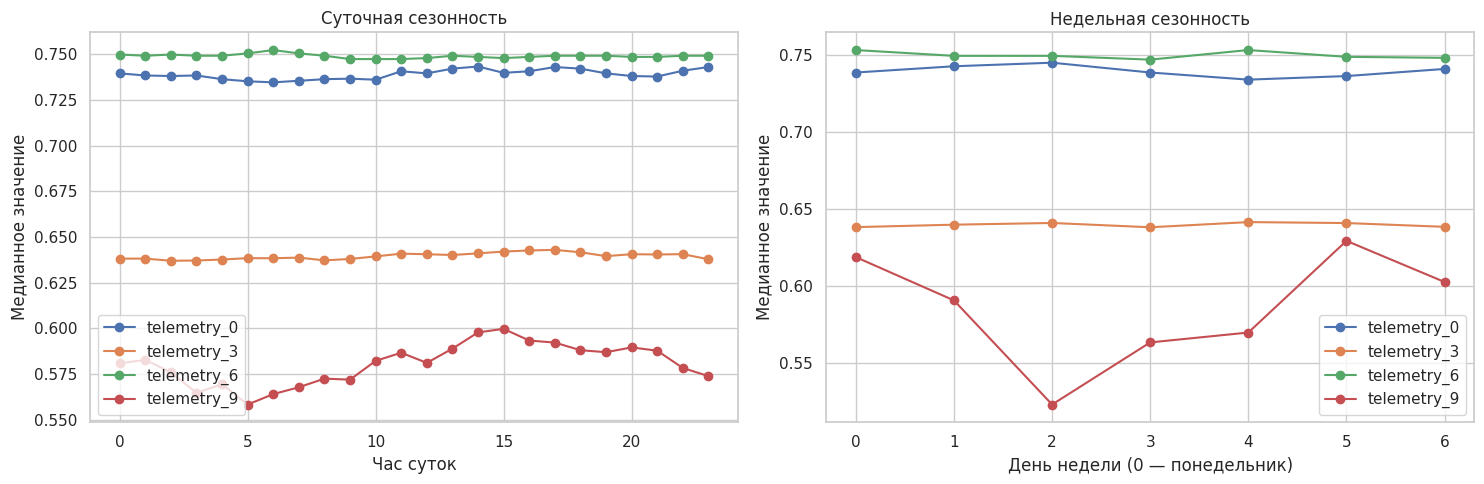

In [15]:
plot_cols = ["telemetry_0", "telemetry_3",
             "telemetry_6", "telemetry_9"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Средний профиль по часам суток
hourly = data_train_clean.groupby(
    data_train_clean["datetime"].dt.hour
)[plot_cols].median()

hourly.plot(ax=axes[0], marker="o")
axes[0].set_title("Суточная сезонность")
axes[0].set_xlabel("Час суток")
axes[0].set_ylabel("Медианное значение")

# Профиль по дням недели
weekly = data_train_clean.groupby(
    data_train_clean["datetime"].dt.dayofweek
)[plot_cols].median()

weekly.plot(ax=axes[1], marker="o")
axes[1].set_title("Недельная сезонность")
axes[1].set_xlabel("День недели (0 — понедельник)")
axes[1].set_ylabel("Медианное значение")

plt.tight_layout()
plt.show()

### 2.1.6. Корреляционный анализ с учётом временных лагов

Связь между показаниями датчиков и концентрацией продукта может проявляться не мгновенно, поскольку технологические процессы обладают инерционностью.

Для исследования временной зависимости рассчитаем коэффициенты корреляции Пирсона между целевой переменной и показаниями телеметрии с лагами 0, 5, 15, 30, 60 и 120 минут.

Для редко измеряемых признаков используется заполнение последним известным значением с ограничением в 120 минут.

Лаговые значения рассчитываются на исходном минутном временном ряде, после чего сопоставляются с лабораторными измерениями. Это позволяет избежать использования будущих данных.

In [16]:
# Полный минутный временной ряд
train_eda_ts = (
    data_train_clean
    .set_index("datetime")[telemetry_cols]
    .copy()
)

# Заполняем редкие измерения только вперёд, максимум на 120 минут
train_eda_ts[sparse_cols] = (
    train_eda_ts[sparse_cols].ffill(limit=120)
)

# Целевая переменная в моменты отбора проб
aligned_target = train_aligned.set_index("datetime")["target"]

# Исследуемые временные лаги
lags = [0, 5, 15, 30, 60, 120]

corr_table = pd.DataFrame(index=telemetry_cols)

for lag in lags:
    # Сдвиг телеметрии назад во времени
    lagged_data = train_eda_ts.shift(lag)

    # Сопоставление с лабораторными замерами
    matched = lagged_data.join(aligned_target, how="inner")

    # Корреляция каждого датчика с концентрацией
    corr_table[lag] = matched[telemetry_cols].corrwith(
        matched["target"]
    )

display(corr_table.round(3))

,0,5,15,30,60,120
telemetry_0,-0.1770,-0.1770,-0.1710,-0.1650,-0.1340,-0.0910
telemetry_1,-0.0440,-0.0350,-0.0570,-0.0490,-0.0350,-0.0050
telemetry_2,-0.0110,-0.0100,0.0020,0.0130,-0.0050,-0.0130
telemetry_3,-0.1270,-0.1320,-0.1790,-0.1440,-0.1220,-0.0880
telemetry_4,-0.0700,-0.0650,-0.0900,-0.1010,-0.0720,-0.0350
telemetry_5,-0.0710,-0.0670,-0.0710,-0.0820,-0.0720,-0.0750
telemetry_6,-0.0900,-0.0840,-0.1080,-0.1080,-0.0950,-0.0540
telemetry_7,-0.0450,-0.0440,-0.0440,-0.0460,-0.0420,-0.0640
telemetry_8,0.0890,0.0930,0.0900,0.0690,0.0930,0.0690
telemetry_9,-0.1200,-0.1180,-0.1210,-0.1150,-0.1140,-0.1010


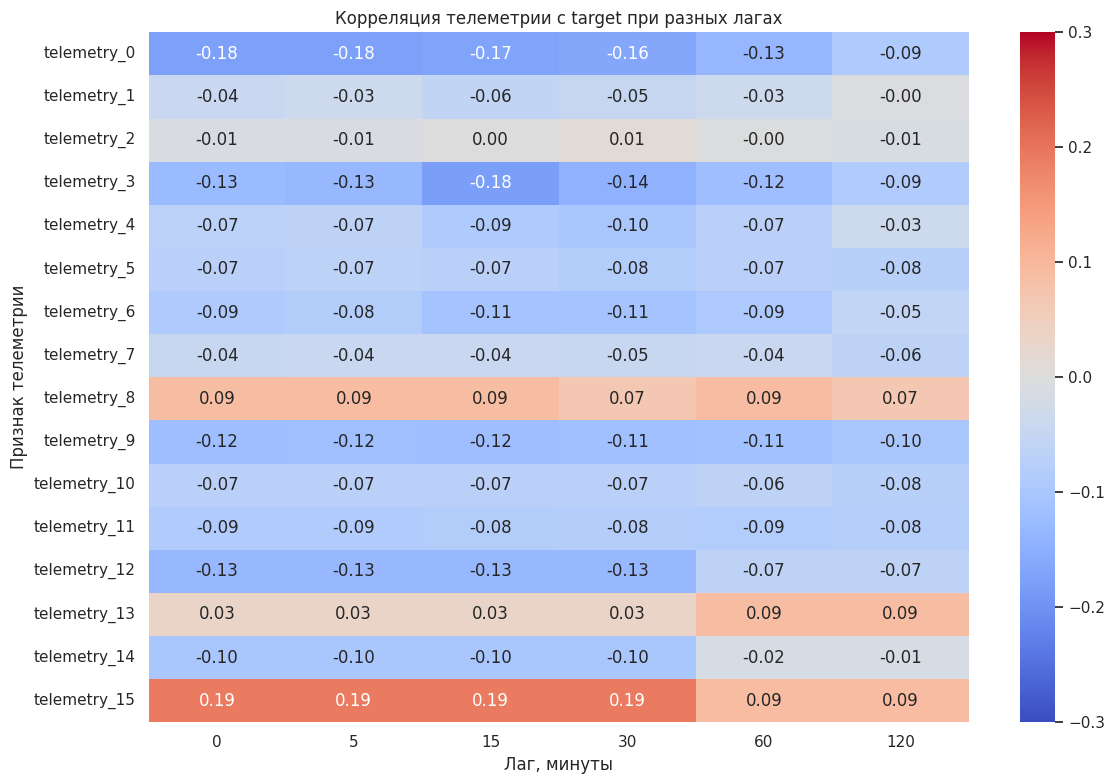

In [17]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_table,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-0.3,
    vmax=0.3
)

plt.title("Корреляция телеметрии с target при разных лагах")
plt.xlabel("Лаг, минуты")
plt.ylabel("Признак телеметрии")
plt.tight_layout()
plt.show()

Топ-6 признаков по абсолютной корреляции:


,0
telemetry_15,0.1907
telemetry_3,0.1789
telemetry_0,0.1773
telemetry_12,0.1322
telemetry_9,0.1206
telemetry_6,0.1082


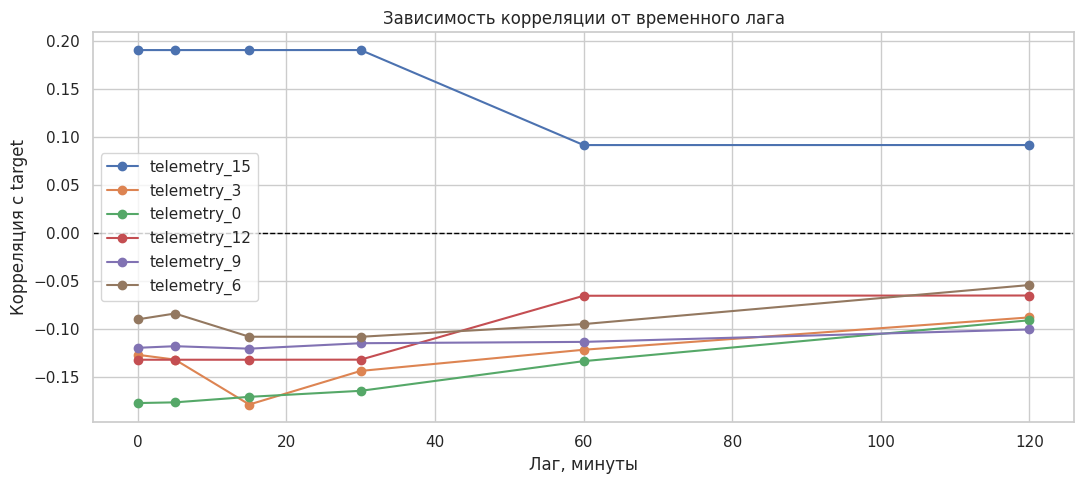

In [18]:
# Максимальная абсолютная корреляция по каждому датчику
top_features = (
    corr_table.abs()
    .max(axis=1)
    .sort_values(ascending=False)
    .head(6)
)

print("Топ-6 признаков по абсолютной корреляции:")
display(top_features.round(4))

# Изменение корреляции в зависимости от лага
corr_table.loc[top_features.index].T.plot(
    marker="o",
    figsize=(11, 5)
)

plt.title("Зависимость корреляции от временного лага")
plt.xlabel("Лаг, минуты")
plt.ylabel("Корреляция с target")
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()

### 2.1.7. Стратегия обработки пропусков и аномалий

На основании проведённого исследования предлагается следующая стратегия предварительной обработки.

**1. Дубликаты временных меток**

Повторяющиеся измерения объединяются путём усреднения значений соответствующих признаков. Это обеспечивает уникальность временного индекса.

**2. Пропуски в часто измеряемых признаках**

Для `telemetry_0`–`telemetry_11` предполагается использование последнего известного значения (`forward fill`) с ограничением до 5 минут. Такой подход позволяет устранить кратковременные сбои без использования будущей информации.

**3. Пропуски в редко измеряемых признаках**

Для `telemetry_12`–`telemetry_15` применяется ограниченное заполнение предыдущим значением на период до 120 минут, соответствующий типичному интервалу измерений.

При дальнейшей разработке могут быть добавлены признаки давности последнего измерения, позволяющие модели оценивать актуальность информации.

**4. Обработка аномалий**

Резкие изменения показаний датчиков не удаляются автоматически, поскольку они могут соответствовать реальным изменениям производственного режима. Выбросы будут дополнительно учитываться при оценке качества моделей.

**5. Обработка целевой переменной**

Отсутствующие лабораторные значения не восстанавливаются интерполяцией. Для обучения используются только реальные лабораторные измерения, поскольку искусственные целевые значения могут привести к искажению результатов.

**6. Предотвращение утечки данных**

Все преобразования выполняются с сохранением временного порядка. Статистики, необходимые для обучения моделей, рассчитываются только на обучающей части данных. Тестовая выборка сохраняется для итоговой проверки качества.

### Выводы по разделу 2.1

В ходе разведочного анализа исследованы структура данных, временная динамика телеметрии, распределение целевой переменной, пропуски, выбросы, сезонность и корреляционные зависимости.

**Основные результаты:**

1. Телеметрия содержит 16 признаков, из которых 12 измеряются ежеминутно, а 4 (`telemetry_12`–`telemetry_15`) — преимущественно каждые 2 часа. Для редко измеряемых признаков целесообразно использовать ограниченное заполнение предыдущим известным значением.

2. Выявлены повторяющиеся временные метки: 1548 в обучающей и 196 в тестовой телеметрии. Дубликаты обработаны путём усреднения измерений.

3. В динамике телеметрии обнаружены существенные изменения режимов работы печи, включая периоды снижения нескольких показателей практически до нуля. Потенциальные выбросы сохранены, поскольку могут отражать реальные технологические процессы.

4. Целевая переменная преимущественно принимает значения в диапазоне 0,1–0,4. Лабораторные измерения выполняются в основном каждые 2–4 часа. Синхронизация с телеметрией выполнена с учётом предполагаемой задержки 15 минут, получено 1772 сопоставленных наблюдения.

5. Анализ сезонности не выявил выраженных суточных и недельных колебаний для большинства рассмотренных признаков. Наиболее заметные изменения характерны для `telemetry_9`, однако их устойчивость требует дополнительной проверки.

6. Корреляционный анализ показал преимущественно слабые линейные связи с концентрацией. Максимальные абсолютные коэффициенты корреляции наблюдаются для `telemetry_15` (0,191), `telemetry_3` (0,179) и `telemetry_0` (0,177). Значимость временных лагов различается между признаками.

**Итог:** использование только текущих показаний телеметрии может быть недостаточным для прогнозирования концентрации. На следующем этапе необходимо сформировать лаговые признаки, скользящие статистики и показатели динамики процесса, позволяющие учитывать временную инерционность системы.

## 2.2. Инжиниринг признаков для временных рядов

### 2.2.1. Подготовка данных для создания временных признаков

Для прогнозирования концентрации недостаточно использовать только показания датчиков в текущий момент времени. Необходимо учитывать предыдущее состояние системы и скорость изменения технологических параметров.

Планируется сформировать следующие группы признаков:

1. **Лаговые признаки** — показания датчиков за 5, 15, 30, 60 и 120 минут до текущего момента.
2. **Скользящие статистики** — среднее значение, стандартное отклонение, минимум и максимум за окна 15, 60 и 120 минут.
3. **Признаки динамики** — абсолютные изменения, скорость и относительный темп изменения показателей.
4. **Признаки актуальности измерений** — время, прошедшее с последнего измерения редко обновляемых датчиков.
5. **Календарные признаки** — циклическое представление времени суток и дня недели.

Для ограничения размерности лаги и скользящие статистики рассчитываются для четырёх выбранных датчиков: `telemetry_0`, `telemetry_3`, `telemetry_6`, `telemetry_9`.

Остальные датчики сохраняются в качестве исходных признаков. В дальнейшем будет выполнена оценка их информативности.

При формировании признаков используются только текущие и предыдущие показания. Будущие значения и целевая переменная не используются.

In [19]:
# Датчики с частыми и редкими измерениями
dense_cols = telemetry_cols[:12]
sparse_cols = telemetry_cols[12:]

# Датчики для расширенных временных признаков
key_cols = [
    "telemetry_0",
    "telemetry_3",
    "telemetry_6",
    "telemetry_9"
]

# Объединяем телеметрию, сохраняя временную историю
full_telemetry = (
    pd.concat([data_train_clean, data_test_clean])
    .sort_values("datetime")
    .set_index("datetime")
)

assert full_telemetry.index.is_unique
assert full_telemetry.index.is_monotonic_increasing

# Заполнение только предыдущими значениями
base = full_telemetry.copy()

base[dense_cols] = base[dense_cols].ffill(limit=5)
base[sparse_cols] = base[sparse_cols].ffill(limit=120)

print("Размер временного ряда:", base.shape)
print("Период:", base.index.min(), "—", base.index.max())

Размер временного ряда: (357745, 16)
Период: 2019-03-01 00:01:00 — 2019-11-04 10:25:00


In [20]:
# Словарь будущих признаков
feature_dict = {
    col: base[col] for col in telemetry_cols
}

# Давность последнего измерения редких датчиков
for col in sparse_cols:
    last_time = (
        full_telemetry.index.to_series()
        .where(full_telemetry[col].notna())
        .ffill()
    )

    age = (
        full_telemetry.index.to_series() - last_time
    ).dt.total_seconds() / 60

    feature_dict[f"{col}_age_min"] = age.where(age <= 120)

# Лаги, статистики и динамика ключевых датчиков
for col in key_cols:

    # Предыдущие значения
    for lag in [5, 15, 30, 60, 120]:
        feature_dict[f"{col}_lag_{lag}m"] = base[col].shift(lag)

    # Скользящие статистики
    for window in [15, 60, 120]:
        rolling = base[col].rolling(
            window=window,
            min_periods=window
        )

        feature_dict[f"{col}_mean_{window}m"] = rolling.mean()
        feature_dict[f"{col}_std_{window}m"] = rolling.std()
        feature_dict[f"{col}_min_{window}m"] = rolling.min()
        feature_dict[f"{col}_max_{window}m"] = rolling.max()

    # Абсолютные изменения
    for lag in [5, 15, 60]:
        feature_dict[f"{col}_delta_{lag}m"] = (
            base[col] - base[col].shift(lag)
        )

    # Скорость и относительное изменение за 15 минут
    previous = base[col].shift(15)
    delta = base[col] - previous

    feature_dict[f"{col}_rate_15m"] = delta / 15

    feature_dict[f"{col}_growth_15m"] = (
        delta / previous.abs().clip(lower=0.05)
    ).clip(-5, 5)

# Циклические календарные признаки
hour = base.index.hour + base.index.minute / 60
weekday = base.index.dayofweek

feature_dict["hour_sin"] = np.sin(2 * np.pi * hour / 24)
feature_dict["hour_cos"] = np.cos(2 * np.pi * hour / 24)
feature_dict["weekday_sin"] = np.sin(2 * np.pi * weekday / 7)
feature_dict["weekday_cos"] = np.cos(2 * np.pi * weekday / 7)

# Формируем таблицу признаков
feature_matrix = pd.DataFrame(
    feature_dict,
    index=base.index
).astype("float32")

print("Количество признаков:", feature_matrix.shape[1])
print("Количество временных записей:", len(feature_matrix))

Количество признаков: 112
Количество временных записей: 357745


In [21]:
# Берём признаки в моменты лабораторных проб
X_train_features = feature_matrix.loc[
    train_aligned["datetime"]
].copy()

# Реальные лабораторные значения
y_train = pd.Series(
    train_aligned["target"].to_numpy(),
    index=X_train_features.index,
    name="target"
)

# Проверяем результат
assert len(X_train_features) == len(y_train)
assert X_train_features.index.is_monotonic_increasing

print("Размер X:", X_train_features.shape)
print("Размер y:", y_train.shape)

print("\nПропуски в созданных признаках:")
display(
    (X_train_features.isna().mean() * 100)
    .sort_values(ascending=False)
    .head(10)
    .round(2)
)

display(X_train_features.head())

Размер X: (1772, 112)
Размер y: (1772,)

Пропуски в созданных признаках:


,0
telemetry_12,0.5600
telemetry_13,0.5600
telemetry_14,0.5600
telemetry_15,0.5600
telemetry_15_age_min,0.5600
telemetry_14_age_min,0.5600
telemetry_13_age_min,0.5600
telemetry_12_age_min,0.5600
telemetry_4,0.0600
telemetry_6,0.0000


,telemetry_0,telemetry_1,telemetry_2,telemetry_3,telemetry_4,telemetry_5,telemetry_6,telemetry_7,telemetry_8,telemetry_9,telemetry_10,telemetry_11,telemetry_12,telemetry_13,telemetry_14,telemetry_15,telemetry_12_age_min,telemetry_13_age_min,telemetry_14_age_min,telemetry_15_age_min,telemetry_0_lag_5m,telemetry_0_lag_15m,telemetry_0_lag_30m,telemetry_0_lag_60m,telemetry_0_lag_120m,telemetry_0_mean_15m,telemetry_0_std_15m,telemetry_0_min_15m,telemetry_0_max_15m,telemetry_0_mean_60m,telemetry_0_std_60m,telemetry_0_min_60m,telemetry_0_max_60m,telemetry_0_mean_120m,telemetry_0_std_120m,telemetry_0_min_120m,telemetry_0_max_120m,telemetry_0_delta_5m,telemetry_0_delta_15m,telemetry_0_delta_60m,telemetry_0_rate_15m,telemetry_0_growth_15m,telemetry_3_lag_5m,telemetry_3_lag_15m,telemetry_3_lag_30m,telemetry_3_lag_60m,telemetry_3_lag_120m,telemetry_3_mean_15m,telemetry_3_std_15m,telemetry_3_min_15m,telemetry_3_max_15m,telemetry_3_mean_60m,telemetry_3_std_60m,telemetry_3_min_60m,telemetry_3_max_60m,telemetry_3_mean_120m,telemetry_3_std_120m,telemetry_3_min_120m,telemetry_3_max_120m,telemetry_3_delta_5m,telemetry_3_delta_15m,telemetry_3_delta_60m,telemetry_3_rate_15m,telemetry_3_growth_15m,telemetry_6_lag_5m,telemetry_6_lag_15m,telemetry_6_lag_30m,telemetry_6_lag_60m,telemetry_6_lag_120m,telemetry_6_mean_15m,telemetry_6_std_15m,telemetry_6_min_15m,telemetry_6_max_15m,telemetry_6_mean_60m,telemetry_6_std_60m,telemetry_6_min_60m,telemetry_6_max_60m,telemetry_6_mean_120m,telemetry_6_std_120m,telemetry_6_min_120m,telemetry_6_max_120m,telemetry_6_delta_5m,telemetry_6_delta_15m,telemetry_6_delta_60m,telemetry_6_rate_15m,telemetry_6_growth_15m,telemetry_9_lag_5m,telemetry_9_lag_15m,telemetry_9_lag_30m,telemetry_9_lag_60m,telemetry_9_lag_120m,telemetry_9_mean_15m,telemetry_9_std_15m,telemetry_9_min_15m,telemetry_9_max_15m,telemetry_9_mean_60m,telemetry_9_std_60m,telemetry_9_min_60m,telemetry_9_max_60m,telemetry_9_mean_120m,telemetry_9_std_120m,telemetry_9_min_120m,telemetry_9_max_120m,telemetry_9_delta_5m,telemetry_9_delta_15m,telemetry_9_delta_60m,telemetry_9_rate_15m,telemetry_9_growth_15m,hour_sin,hour_cos,weekday_sin,weekday_cos
datetime,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2019-03-13 16:45:00,0.7870,0.4976,0.3090,0.6402,0.9195,0.8782,0.7535,0.4335,0.4742,0.6978,0.7701,0.6480,0.3043,0.6800,0.4432,0.2066,45.0000,45.0000,45.0000,45.0000,0.7861,0.7838,0.7827,0.7853,0.7789,0.7856,0.0011,0.7838,0.7870,0.7846,0.0015,0.7827,0.7873,0.7845,0.0017,0.7789,0.7873,0.0009,0.0032,0.0017,0.0002,0.0041,0.6588,0.6554,0.6676,0.6613,0.6885,0.6542,0.0108,0.6402,0.6765,0.6597,0.0087,0.6402,0.6785,0.6639,0.0098,0.6402,0.6851,-0.0186,-0.0152,-0.0212,-0.0010,-0.0232,0.7548,0.7542,0.7554,0.7542,0.7542,0.7537,0.0009,0.7530,0.7548,0.7541,0.0009,0.7530,0.7554,0.7540,0.0009,0.7523,0.7554,-0.0013,-0.0006,-0.0006,-0.0000,-0.0009,0.6978,0.6981,0.7009,0.7053,0.7062,0.6977,0.0002,0.6975,0.6981,0.7007,0.0027,0.6975,0.7053,0.7035,0.0035,0.6975,0.7073,0.0000,-0.0003,-0.0075,-0.0000,-0.0004,-0.9469,-0.3214,0.9749,-0.2225
2019-03-13 20:45:00,0.7824,0.4976,0.3015,0.6488,0.9195,0.8515,0.7554,0.4707,0.4765,0.7126,0.7523,0.6294,0.1056,0.6100,0.4432,0.3293,45.0000,45.0000,45.0000,45.0000,0.7798,0.7789,0.7772,0.7679,0.7725,0.7796,0.0018,0.7775,0.7824,0.7752,0.0048,0.7673,0.7824,0.7745,0.0044,0.7668,0.7824,0.0026,0.0035,0.0145,0.0002,0.0045,0.6590,0.6609,0.6431,0.6589,0.6513,0.6464,0.0094,0.6301,0.6612,0.6469,0.0089,0.6301,0.6626,0.6419,0.0120,0.6111,0.6668,-0.0102,-0.0121,-0.0101,-0.0008,-0.0183,0.7535,0.7554,0.7554,0.7548,0.7530,0.7542,0.0008,0.7530,0.7554,0.7544,0.0007,0.7530,0.7554,0.7545,0.0007,0.7530,0.7554,0.0019,0.0000,0.0006,0.0000,0.0000,0.7120,0.7115,0.7126,0.7209,0.7343,0.7119,0.0003,0.7115,0.7126,0.7137,0.0025,0.7115,0.7195,0.7212,0.0081,0.7115,0.7343,0.0006,0.0011,-0.0083,0.0001,0.0016,-0.7518,0.6593,0.9749,-0.2225
2019-03-14 00:45:00,0.7885,0.4975,0.3003,0.6337,0.9195,0.8761,0.7535,0.4438,0.4742,0.7056

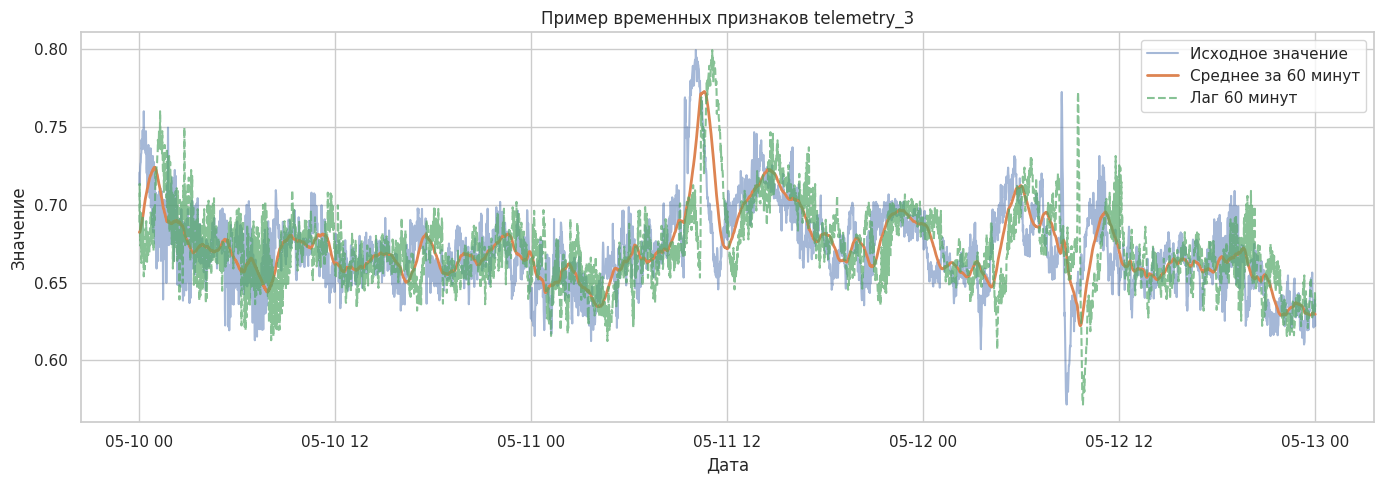

In [22]:
# Пример: один из ключевых датчиков
col = "telemetry_3"

# Берём небольшой временной интервал
example = feature_matrix.loc[
    "2019-05-10":"2019-05-12"
]

plt.figure(figsize=(14, 5))

plt.plot(
    example.index,
    example[col],
    label="Исходное значение",
    alpha=0.5
)

plt.plot(
    example.index,
    example[f"{col}_mean_60m"],
    label="Среднее за 60 минут",
    linewidth=2
)

plt.plot(
    example.index,
    example[f"{col}_lag_60m"],
    label="Лаг 60 минут",
    linestyle="--",
    alpha=0.7
)

plt.title("Пример временных признаков telemetry_3")
plt.xlabel("Дата")
plt.ylabel("Значение")
plt.legend()
plt.tight_layout()
plt.show()

### 2.2.2. Обоснование выбора признаков

Созданные признаки отражают различные характеристики технологического процесса:

- **Лаговые признаки** позволяют учитывать инерционность процесса обжига и возможную задержку реакции концентрации на изменение параметров печи.
- **Скользящее среднее** отражает общее состояние оборудования и снижает влияние кратковременных колебаний датчиков.
- **Стандартное отклонение** характеризует стабильность технологического процесса.
- **Минимальные и максимальные значения** позволяют обнаруживать кратковременные экстремальные режимы работы.
- **Разности и скорости изменения** помогают описывать переходные процессы, которые могут влиять на качество продукции.
- **Давность измерения** позволяет учитывать снижение актуальности показаний редко обновляемых датчиков.
- **Календарные признаки** добавлены для проверки возможного влияния времени суток и дня недели.

Временные признаки в первую очередь создаются для `telemetry_0`, `telemetry_3`, `telemetry_6` и `telemetry_9`, выбранных по результатам разведочного анализа. Признаки `telemetry_12` и `telemetry_15`, также показавшие заметную корреляцию с концентрацией, сохраняются в исходном виде с добавлением информации о давности измерения.

**Снижение размерности методом PCA на данном этапе не применяется**, поскольку важна интерпретируемость прогноза. Кроме того, преобразование PCA затруднило бы установление связи между конкретными датчиками и прогнозируемой концентрацией.

После построения базовых моделей будет выполнена оценка важности признаков и при необходимости исключены избыточные или малоинформативные переменные.

## 2.3. Построение прогнозных моделей

### 2.3.1. Выбор архитектур прогнозных моделей

Задача прогнозирования концентрации представляет собой регрессию на основе временных рядов. Временная динамика учитывается с помощью предварительно созданных лаговых признаков, скользящих статистик и характеристик изменения показаний.

Для сравнения выбраны три подхода:

**1. Ridge Regression**

Линейная регрессия с L2-регуляризацией. Используется в качестве базовой интерпретируемой модели. Регуляризация позволяет уменьшить влияние мультиколлинеарности, возникающей из-за большого количества взаимосвязанных временных признаков.

**2. Random Forest Regressor**

Ансамбль деревьев решений, позволяющий моделировать нелинейные зависимости и взаимодействия между показателями телеметрии. Подходит для табличных данных и относительно небольшого количества размеченных наблюдений.

**3. HistGradientBoostingRegressor**

Градиентный бустинг на деревьях решений. Модель последовательно исправляет ошибки предыдущих деревьев и способна выявлять сложные нелинейные зависимости. Использует гистограммное разбиение признаков, что повышает вычислительную эффективность.

**Подходы, менее подходящие для данной задачи:**

- **ARIMA/SARIMA в стандартном виде:** предполагают регулярный временной ряд целевой переменной, тогда как лабораторные измерения нерегулярны. Кроме того, стандартная одномерная постановка не учитывает множество телеметрических показателей.
- **LSTM и Transformer:** потенциально применимы, но требуют более сложной подготовки последовательностей и регуляризации. При наличии только 1772 размеченных наблюдений существует повышенный риск переобучения.
- **KNN-регрессия:** при большом количестве взаимосвязанных признаков расстояния между наблюдениями становятся менее информативными, а качество сильно зависит от масштабирования.

Поэтому для данной лабораторной работы выбраны модели, ориентированные на табличные признаки с явно сформированной временной историей.

### 2.3.2. Разделение данных

Для оценки качества применяется хронологическое разделение обучающих данных:

- Первые 80% наблюдений используются для обучения моделей.
- Последние 20% — для валидации и сравнения моделей.

Случайное перемешивание не применяется, поскольку в реальных условиях модель должна прогнозировать будущие значения концентрации на основе предыдущей истории процесса.

Предоставленная тестовая выборка сохраняется для окончательной независимой оценки выбранной модели.

Заполнение пропущенных значений и масштабирование признаков выполняются внутри `Pipeline`. Параметры этих преобразований определяются исключительно на обучающей части.

In [23]:
# Упорядочиваем наблюдения по времени
X = X_train_features.sort_index()
y = y_train.loc[X.index]

# Хронологическое разделение 80/20
split_idx = int(len(X) * 0.8)

X_train_ml = X.iloc[:split_idx]
X_val = X.iloc[split_idx:]

y_train_ml = y.iloc[:split_idx]
y_val = y.iloc[split_idx:]

print("Обучающая выборка:", X_train_ml.shape)
print("Валидационная выборка:", X_val.shape)

print("\nПериод обучения:")
print(X_train_ml.index.min(), "—", X_train_ml.index.max())

print("\nПериод валидации:")
print(X_val.index.min(), "—", X_val.index.max())

assert X_train_ml.index.max() < X_val.index.min()

Обучающая выборка: (1417, 112)
Валидационная выборка: (355, 112)

Период обучения:
2019-03-13 16:45:00 — 2019-08-23 22:45:00

Период валидации:
2019-08-24 00:45:00 — 2019-10-07 18:45:00


In [24]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)

from time import perf_counter

# Три регрессионные модели
models = {
    "Ridge": Pipeline([
        ("imputer", SimpleImputer(
            strategy="median", add_indicator=True
        )),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=20.0))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(
            strategy="median", add_indicator=True
        )),
        ("model", RandomForestRegressor(
            n_estimators=150,
            max_depth=12,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(
            strategy="median", add_indicator=True
        )),
        ("model", HistGradientBoostingRegressor(
            max_iter=250,
            learning_rate=0.05,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            random_state=42
        ))
    ])
}

# Обучение и измерение времени
training_times = {}

for name, model in models.items():
    start = perf_counter()

    model.fit(X_train_ml, y_train_ml)

    training_times[name] = perf_counter() - start

    print(f"{name}: {training_times[name]:.2f} сек")

Ridge: 0.04 сек
Random Forest: 13.48 сек
Gradient Boosting: 1.75 сек


In [25]:
# первичные метрики
from sklearn.metrics import mean_absolute_error, mean_squared_error

def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    # MAPE: нулевые значения target исключаем
    mask = np.abs(y_true) > 1e-8
    mape = (
        np.mean(np.abs(
            (y_true[mask] - y_pred[mask]) / y_true[mask]
        )) * 100
        if mask.any() else np.nan
    )

    wape = (
        np.sum(np.abs(y_true - y_pred)) /
        np.sum(np.abs(y_true)) * 100
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE, %": mape,
        "WAPE, %": wape
    }


results = []
val_predictions = {}

for name, model in models.items():
    # Предсказания на валидации
    y_pred = model.predict(X_val)
    val_predictions[name] = y_pred

    metrics = calculate_metrics(y_val, y_pred)
    metrics["Модель"] = name
    metrics["Время, с"] = training_times[name]

    results.append(metrics)

# Базовый прогноз — медиана обучающей концентрации
baseline_pred = np.full(
    len(y_val), y_train_ml.median()
)

baseline_metrics = calculate_metrics(y_val, baseline_pred)
baseline_metrics["Модель"] = "Baseline (медиана)"
baseline_metrics["Время, с"] = 0.0
results.append(baseline_metrics)

results_df = (
    pd.DataFrame(results)
    .set_index("Модель")
    .sort_values("MAE")
)

display(results_df.round(4))

,MAE,RMSE,"MAPE, %","WAPE, %","Время, с"
Модель,,,,,
Gradient Boosting,0.0633,0.0789,33.9263,28.0100,1.7532
Random Forest,0.0652,0.0817,36.2939,28.8784,13.4816
Ridge,0.0694,0.0857,39.3558,30.7238,0.0403
Baseline (медиана),0.0719,0.0861,41.1348,31.8215,0.0000


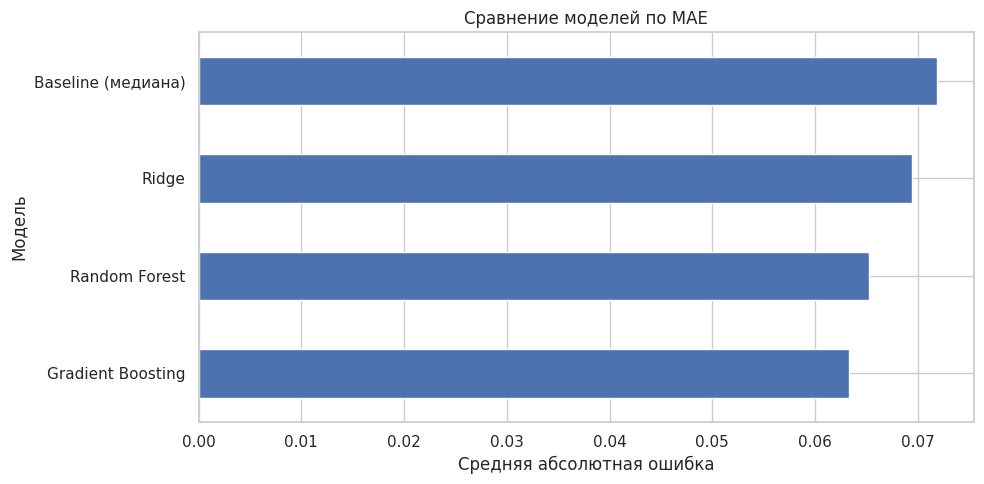

Лучшая модель по MAE:
Gradient Boosting


In [26]:
plt.figure(figsize=(10, 5))

results_df["MAE"].sort_values().plot(
    kind="barh"
)

plt.title("Сравнение моделей по MAE")
plt.xlabel("Средняя абсолютная ошибка")
plt.ylabel("Модель")
plt.tight_layout()
plt.show()

print("Лучшая модель по MAE:")
print(results_df["MAE"].idxmin())

### 2.3.3. Предварительное сравнение прогнозных моделей

Были обучены три модели: Ridge Regression, Random Forest и HistGradientBoostingRegressor. В качестве базового подхода использовался постоянный прогноз медианного значения концентрации.

По результатам валидации лучшей оказалась модель **Gradient Boosting**:

- MAE = 0.0633;
- RMSE = 0.0789;
- MAPE = 33.93%;
- WAPE = 28.01%;
- Время обучения = 1.75 с.

По сравнению с базовым прогнозом удалось снизить MAE приблизительно на 12%.

Random Forest показал близкие результаты, однако потребовал значительно больше вычислительного времени. Ridge Regression уступила ансамблевым моделям, что может указывать на наличие нелинейных зависимостей между параметрами технологического процесса и концентрацией.

Вместе с тем значения относительных ошибок остаются достаточно высокими. Поэтому необходимо дополнительно исследовать динамику прогнозов, направление изменений концентрации и статистические свойства ошибок.

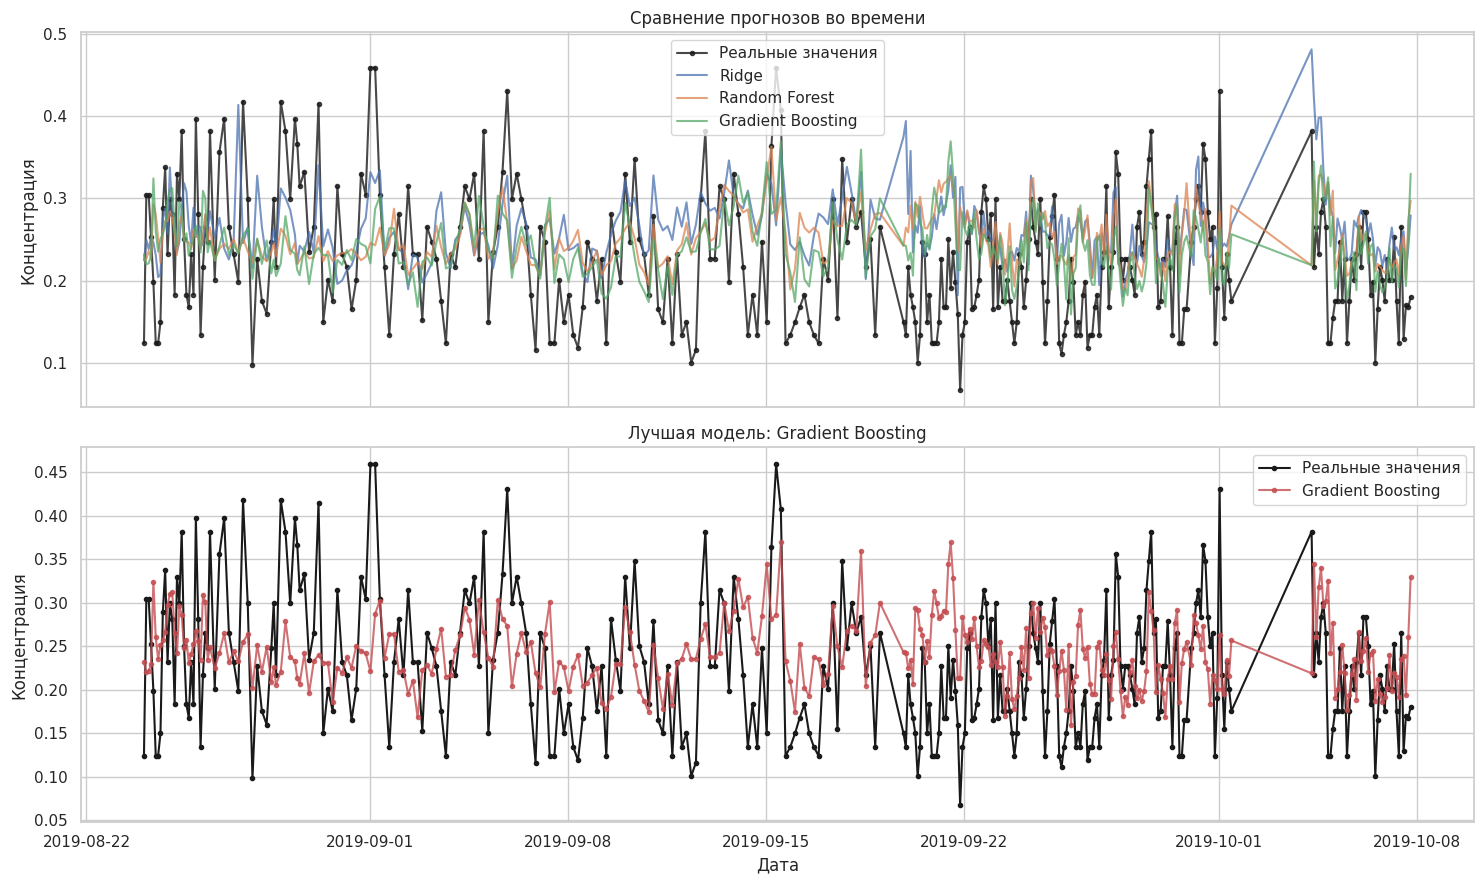

In [27]:
fig, axes = plt.subplots(
    2, 1, figsize=(15, 9), sharex=True
)

# Все модели на одном графике
axes[0].plot(
    y_val.index, y_val,
    "k.-", label="Реальные значения", alpha=0.8
)

for name, pred in val_predictions.items():
    axes[0].plot(
        y_val.index, pred,
        label=name, alpha=0.75
    )

axes[0].set_title("Сравнение прогнозов во времени")
axes[0].set_ylabel("Концентрация")
axes[0].legend()

# Отдельно лучшая модель
best_name = results_df.loc[
    list(models.keys()), "MAE"
].idxmin()

best_pred = val_predictions[best_name]

axes[1].plot(
    y_val.index, y_val,
    "k.-", label="Реальные значения"
)

axes[1].plot(
    y_val.index, best_pred,
    "r.-", label=best_name, alpha=0.8
)

axes[1].set_title(f"Лучшая модель: {best_name}")
axes[1].set_ylabel("Концентрация")
axes[1].set_xlabel("Дата")
axes[1].legend()

plt.tight_layout()
plt.show()

### Оценка направления прогнозируемых изменений

Дополнительно к стандартным регрессионным метрикам используется Directional Accuracy — доля случаев, когда модель правильно определяет направление изменения концентрации между последовательными лабораторными измерениями.

Для каждого интервала сравниваются знаки изменения реальной и прогнозируемой концентрации:


$$
 DA = \frac{1}{N}\sum_{i=1}^{N} I\left(\operatorname{sign}(\Delta y_i)= \operatorname{sign}(\Delta\hat{y}_i)\right)
$$

где:
- $\Delta y_i$ — изменение фактической концентрации;
- $\Delta\hat{y}_i$ — изменение прогноза;
- $I$ — индикатор совпадения направлений.


В расчёт включаются интервалы продолжительностью не более 4 часов, для которых фактическая концентрация изменилась. Такой подход позволяет исключить длительные разрывы между измерениями и оценить способность модели отслеживать динамику процесса.

In [28]:
# Изменения реальной концентрации
true_changes = np.diff(y_val.to_numpy())

# Интервалы между лабораторными измерениями
time_gaps = (
    y_val.index.to_series()
    .diff()
    .dt.total_seconds()
    .to_numpy()[1:] / 3600
)

# Только изменения на интервалах до 4 часов
mask = (
    (time_gaps > 0) &
    (time_gaps <= 4) &
    (np.abs(true_changes) > 1e-8)
)

true_direction = np.sign(true_changes[mask])

direction_results = []

for name, pred in val_predictions.items():
    pred_changes = np.diff(pred)
    pred_direction = np.sign(pred_changes[mask])

    accuracy = np.mean(
        true_direction == pred_direction
    )

    direction_results.append({
        "Модель": name,
        "Directional Accuracy, %": accuracy * 100
    })

direction_df = pd.DataFrame(
    direction_results
).set_index("Модель")

# Ориентир: всегда выбирать наиболее частое направление
majority_accuracy = max(
    np.mean(true_direction > 0),
    np.mean(true_direction < 0)
) * 100

print("Количество оцениваемых изменений:", mask.sum())
print(f"Частотный ориентир: {majority_accuracy:.2f}%")

display(direction_df.round(2))

Количество оцениваемых изменений: 333
Частотный ориентир: 50.45%


,"Directional Accuracy, %"
Модель,
Ridge,54.0500
Random Forest,59.1600
Gradient Boosting,56.1600


### 2.3.4. Анализ остатков модели

Остатки прогнозной модели позволяют определить наличие систематических ошибок.

Проверяются три свойства:

**1. Нормальность распределения**

Оценивается с помощью теста Д'Агостино — Пирсона. Значительное отклонение от нормального распределения может свидетельствовать о наличии выбросов, асимметрии или сложной структуры ошибок.

**2. Автокорреляция**

Проверяется с помощью теста Льюнга — Бокса. Автокорреляция означает, что последовательные ошибки связаны между собой и модель могла не учесть часть временных закономерностей.

**3. Гетероскедастичность**

Проверяется с помощью теста Бройша — Пагана. Она означает, что разброс ошибок зависит от величины прогнозируемой концентрации.

Для статистических тестов используется уровень значимости 0.05. Если p-value меньше 0.05, соответствующая нулевая гипотеза отвергается.

Поскольку лабораторные измерения нерегулярны, автокорреляция оценивается в последовательности наблюдений, а не на строго равномерной временной сетке. Результаты тестов следует интерпретировать с учётом этого ограничения.

In [29]:
from scipy import stats
from statsmodels.stats.diagnostic import (
    acorr_ljungbox,
    het_breuschpagan
)
import statsmodels.api as sm

# Остатки лучшей модели
residuals = y_val.to_numpy() - best_pred

# 1. Нормальность
normal_stat, normal_p = stats.normaltest(residuals)

# 2. Автокорреляция
ljung_box = acorr_ljungbox(
    residuals,
    lags=[1, 5, 10],
    return_df=True
)

# 3. Гетероскедастичность
exog = sm.add_constant(best_pred, has_constant="add")

bp_stat, bp_p, _, _ = het_breuschpagan(
    residuals, exog
)

print(f"Нормальность: p-value = {normal_p:.5f}")
print(f"Гетероскедастичность: p-value = {bp_p:.5f}")

print("\nАвтокорреляция:")
display(ljung_box.round(5))

print("\nИнтерпретация:")
print(
    "Нормальность:",
    "отвергается" if normal_p < 0.05
    else "не отвергается"
)

print(
    "Постоянство дисперсии:",
    "отвергается" if bp_p < 0.05
    else "не отвергается"
)

Нормальность: p-value = 0.20747
Гетероскедастичность: p-value = 0.00000

Автокорреляция:


,lb_stat,lb_pvalue
1,58.1063,0.0000
5,112.1099,0.0000
10,143.6947,0.0000



Интерпретация:
Нормальность: не отвергается
Постоянство дисперсии: отвергается


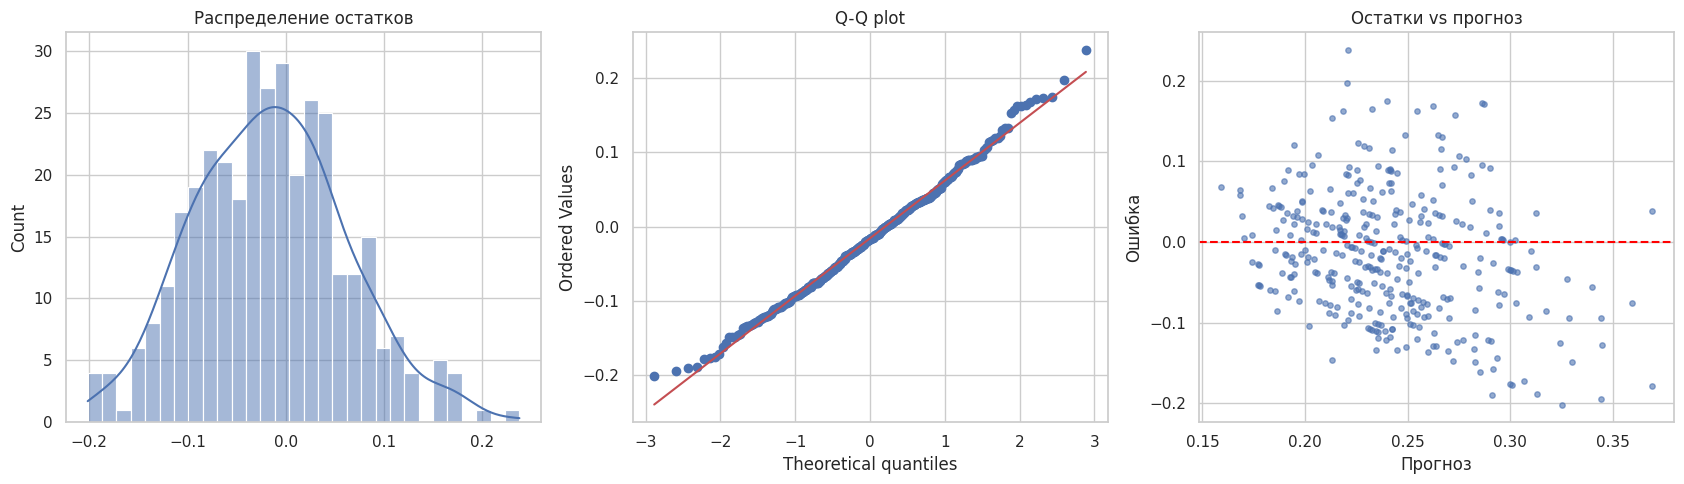

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Распределение ошибок
sns.histplot(
    residuals,
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Распределение остатков")

# Q-Q plot
stats.probplot(
    residuals,
    dist="norm",
    plot=axes[1]
)
axes[1].set_title("Q-Q plot")

# Ошибки относительно прогноза
axes[2].scatter(
    best_pred, residuals,
    alpha=0.6, s=15
)
axes[2].axhline(
    0, color="red", linestyle="--"
)
axes[2].set_title("Остатки vs прогноз")
axes[2].set_xlabel("Прогноз")
axes[2].set_ylabel("Ошибка")

plt.tight_layout()
plt.show()

### Выводы по анализу прогнозов и остатков

На валидационной выборке Gradient Boosting показал наименьшую ошибку прогнозирования концентрации (MAE = 0.0633). Однако по метрике определения направления изменений лучший результат продемонстрировал Random Forest — 59.16% против 56.16% у Gradient Boosting.

Визуальный анализ показал, что прогнозы моделей более сглажены по сравнению с фактическими лабораторными измерениями. Модели способны оценивать общий уровень концентрации, но недостаточно точно воспроизводят отдельные резкие изменения.

Проверка остатков показала:

- Нормальность распределения не отвергается (p = 0.20747).
- Присутствует статистически значимая автокорреляция остатков (p < 0.05).
- Обнаружена гетероскедастичность ошибок (p < 0.05).

Таким образом, наименьшую точечную ошибку обеспечивает Gradient Boosting, однако наличие временной зависимости и неоднородности ошибок свидетельствует о возможностях дальнейшего улучшения модели.

### 2.3.5. Анализ важности признаков

Для интерпретации Gradient Boosting используется метод Permutation Importance.

Метод оценивает изменение качества модели при случайном перемешивании значений каждого признака.

В качестве метрики используется MAE. Положительная важность означает, что после перемешивания признака ошибка увеличивается, следовательно, признак полезен для прогнозирования.

Поскольку многие лаговые и скользящие признаки коррелируют друг с другом, их индивидуальная важность может быть занижена. Полученные оценки отражают вклад признаков в конкретную модель, а не причинно-следственное влияние датчиков на концентрацию.

In [31]:
from sklearn.inspection import permutation_importance

# Оценка важности на валидационной выборке
perm = permutation_importance(
    models[best_name],
    X_val,
    y_val,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Признак": X_val.columns,
    "Важность": perm.importances_mean,
    "Стд. отклонение": perm.importances_std
})

importance_df = importance_df.sort_values(
    "Важность", ascending=False
)

print("Топ-15 наиболее важных признаков:")
display(importance_df.head(15).round(5))

Топ-15 наиболее важных признаков:


,Признак,Важность,Стд. отклонение
12,telemetry_12,0.0030,0.0003
15,telemetry_15,0.0017,0.0008
11,telemetry_11,0.0009,0.0002
97,telemetry_9_min_60m,0.0008,0.0003
14,telemetry_14,0.0007,0.0001
13,telemetry_13,0.0007,0.0003
34,telemetry_0_std_120m,0.0006,0.0004
45,telemetry_3_lag_60m,0.0005,0.0002
87,telemetry_9_lag_15m,0.0004,0.0001
1,telemetry_1,0.0004,0.0002


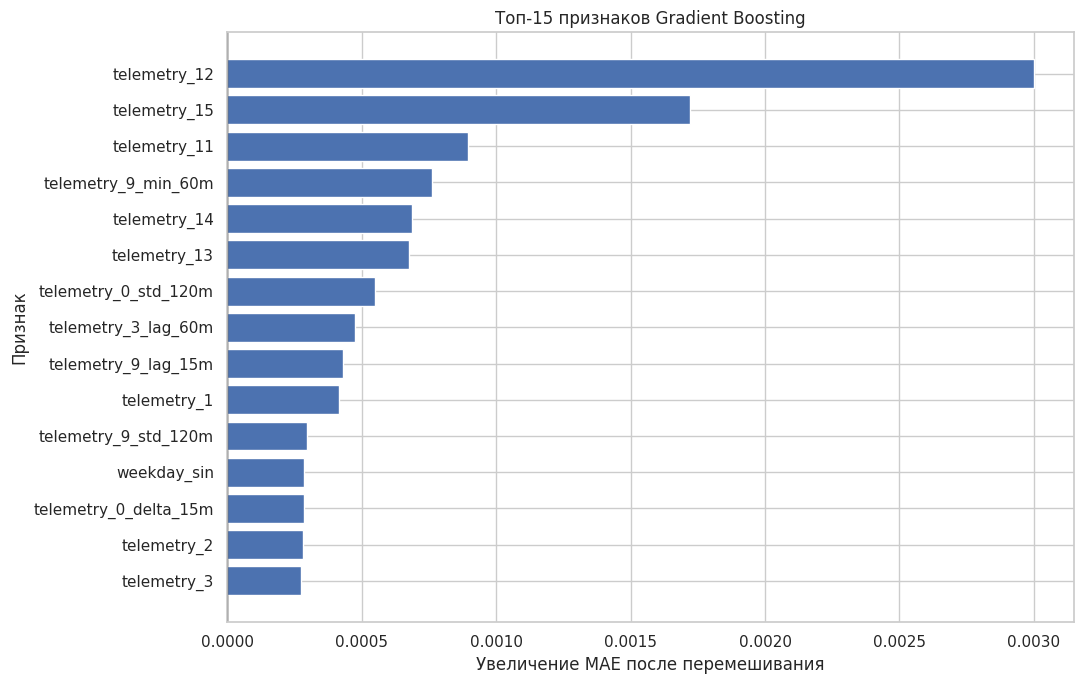

In [32]:
top15 = importance_df.head(15).sort_values("Важность")

plt.figure(figsize=(11, 7))

plt.barh(
    top15["Признак"],
    top15["Важность"]
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Топ-15 признаков Gradient Boosting")
plt.xlabel("Увеличение MAE после перемешивания")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()

### 2.3.6. Сравнение по информационным критериям

Информационные критерии AIC (Akaike Information Criterion) и BIC (Bayesian Information Criterion) используются для сравнения статистических моделей с учётом качества подгонки и сложности.
$$AIC = 2k - 2\ln(L)$$

$$BIC = k\ln(n)-2\ln(L)$$

где:
- k — количество оцениваемых параметров;
- n — количество наблюдений;
- L — максимальное значение функции правдоподобия.

Для сравнения используются три модели OLS:

1. Константная модель без признаков.
2. Линейная модель с текущими показаниями выбранных датчиков.
3. Линейная модель с текущими показаниями и временными признаками.

Предпочтительны меньшие значения AIC и BIC. Сравнение проводится на одинаковом обучающем наборе данных.

Критерии рассматриваются в рамках статистических моделей OLS и не используются для прямого ранжирования Ridge, Random Forest и Gradient Boosting.

In [33]:
import statsmodels.api as sm

# Наборы признаков для статистических моделей
current_cols = [
    "telemetry_0", "telemetry_3",
    "telemetry_6", "telemetry_9",
    "telemetry_15"
]

history_cols = current_cols + [
    "telemetry_0_mean_60m",
    "telemetry_3_mean_60m",
    "telemetry_9_mean_60m",
    "telemetry_3_delta_15m",
    "telemetry_9_std_60m"
]

ols_configs = {
    "OLS (константа)": [],
    "OLS (текущие)": current_cols,
    "OLS (с историей)": history_cols
}

aic_bic_results = []

for name, cols in ols_configs.items():
    # Константа и выбранные признаки
    X_ols = pd.DataFrame(
        {"const": 1.0},
        index=X_train_ml.index
    )

    if cols:
        values = X_train_ml[cols]
        values = values.fillna(values.median())
        X_ols = pd.concat([X_ols, values], axis=1)

    # Статистическая модель на обучающих данных
    ols_model = sm.OLS(y_train_ml, X_ols).fit()

    aic_bic_results.append({
        "Модель": name,
        "AIC": ols_model.aic,
        "BIC": ols_model.bic,
        "R²": ols_model.rsquared
    })

aic_bic_df = pd.DataFrame(
    aic_bic_results
).set_index("Модель")

display(aic_bic_df.round(4))

,AIC,BIC,R²
Модель,,,
OLS (константа),-2666.5744,-2661.3181,0.0000
OLS (текущие),-2829.3887,-2797.8509,0.1148
OLS (с историей),-2839.9716,-2782.1524,0.1276


In [34]:
efficiency_results = []

for name, model in models.items():
    # Прогрев перед измерением
    model.predict(X_val)

    prediction_times = []

    for _ in range(10):
        start = perf_counter()
        model.predict(X_val)
        prediction_times.append(
            (perf_counter() - start) * 1000
        )

    efficiency_results.append({
        "Модель": name,
        "Обучение, с": training_times[name],
        "Прогноз 355 строк, мс": np.median(prediction_times),
        "MAE": results_df.loc[name, "MAE"]
    })

efficiency_df = pd.DataFrame(
    efficiency_results
).set_index("Модель")

display(efficiency_df.round(4))

,"Обучение, с","Прогноз 355 строк, мс",MAE
Модель,,,
Ridge,0.0403,3.1429,0.0694
Random Forest,13.4816,64.7952,0.0652
Gradient Boosting,1.7532,25.0462,0.0633


### Выводы по важности признаков и вычислительной эффективности

По результатам Permutation Importance наиболее значимыми для Gradient Boosting оказались `telemetry_12`, `telemetry_15` и `telemetry_11`.

Несмотря на редкую периодичность измерения, признаки `telemetry_12` и `telemetry_15` вносят существенный вклад в качество прогнозирования. Также среди информативных признаков присутствуют скользящие статистики и лаги, что подтверждает целесообразность учёта временной динамики.

Сравнение статистических моделей OLS показало, что минимальный AIC достигается при использовании временных признаков (−2839,97), тогда как BIC отдаёт предпочтение более простой модели с текущими измерениями (−2797,85).

По сочетанию качества и вычислительной эффективности среди трёх основных моделей предпочтительна Gradient Boosting:

- MAE = 0.0633;
- Время обучения = 1.75 с;
- Время прогнозирования 355 наблюдений ≈ 25 мс.

Однако результаты анализа остатков указывают на наличие необъяснённой временной зависимости, а качество определения направления изменений остаётся ограниченным.

**Для окончательной оценки необходимо проверить выбранную модель на независимой тестовой выборке, не использовавшейся при обучении и выборе архитектуры.**

## Финальное тестирование модели

### 2.3.7. Финальная оценка на тестовой выборке

Для итоговой проверки используется независимый тестовый период с 7 октября по 4 ноября 2019 года.

Модель Gradient Boosting выбрана на основании результатов валидации. Перед тестированием она повторно обучается на всех 1772 доступных обучающих наблюдениях.

Тестовые лабораторные измерения синхронизируются с телеметрией с использованием того же предположения о задержке 15 минут.

При тестировании не производится подбор гиперпараметров или изменение признаков на основании тестовых результатов. Это необходимо для объективной оценки обобщающей способности модели.

In [35]:
# Подготавливаем лабораторные измерения теста
test_lab = target_test.rename(
    columns={"datetime": "lab_time"}
).copy()

test_lab["sample_time"] = (
    test_lab["lab_time"] - pd.Timedelta(minutes=LAB_DELAY)
)

# Сопоставляем с ранее рассчитанными признаками
test_aligned = pd.merge_asof(
    test_lab.sort_values("sample_time"),
    feature_matrix.reset_index().sort_values("datetime"),
    left_on="sample_time",
    right_on="datetime",
    direction="backward",
    tolerance=pd.Timedelta(minutes=1)
)

# Оставляем записи с доступной телеметрией
test_aligned = test_aligned.dropna(
    subset=["datetime"]
).reset_index(drop=True)

# Формируем X_test и y_test
X_test = test_aligned[X.columns].copy()
X_test.index = pd.DatetimeIndex(test_aligned["datetime"])

y_test = pd.Series(
    test_aligned["target"].to_numpy(),
    index=X_test.index,
    name="target"
)

assert len(X_test) == len(y_test)
assert X_test.index.min() > X.index.max()

print("Тестовая выборка:", X_test.shape)
print("Целевая переменная:", y_test.shape)
print("Период:", X_test.index.min(), "—", X_test.index.max())

Тестовая выборка: (318, 112)
Целевая переменная: (318,)
Период: 2019-10-07 22:45:00 — 2019-11-04 08:45:00


In [36]:
from sklearn.base import clone

# Создаём новую модель с выбранными параметрами
final_model = clone(models[best_name])

# Обучаем на всей обучающей выборке
final_model.fit(X, y)

# Получаем прогнозы на независимом тесте
test_pred = final_model.predict(X_test)

# Сравнение с базовой моделью
baseline_test = np.full(len(y_test), y.median())

test_results = pd.DataFrame({
    best_name: calculate_metrics(y_test, test_pred),
    "Baseline": calculate_metrics(y_test, baseline_test)
}).T

display(test_results.round(4))

,MAE,RMSE,"MAPE, %","WAPE, %"
Gradient Boosting,0.0615,0.0770,33.7644,29.3496
Baseline,0.0768,0.0888,45.7627,36.6391


In [37]:
# Изменения реальной и прогнозируемой концентрации
true_diff = np.diff(y_test.to_numpy())
pred_diff = np.diff(test_pred)

# Учитываем интервалы не более 4 часов
gaps = (
    y_test.index.to_series()
    .diff()
    .dt.total_seconds()
    .to_numpy()[1:] / 3600
)

valid = (
    (gaps > 0) &
    (gaps <= 4) &
    (np.abs(true_diff) > 1e-8)
)

direction_accuracy = np.mean(
    np.sign(true_diff[valid]) ==
    np.sign(pred_diff[valid])
) * 100

print("Количество интервалов:", valid.sum())
print(f"Directional Accuracy: {direction_accuracy:.2f}%")

Количество интервалов: 299
Directional Accuracy: 56.19%


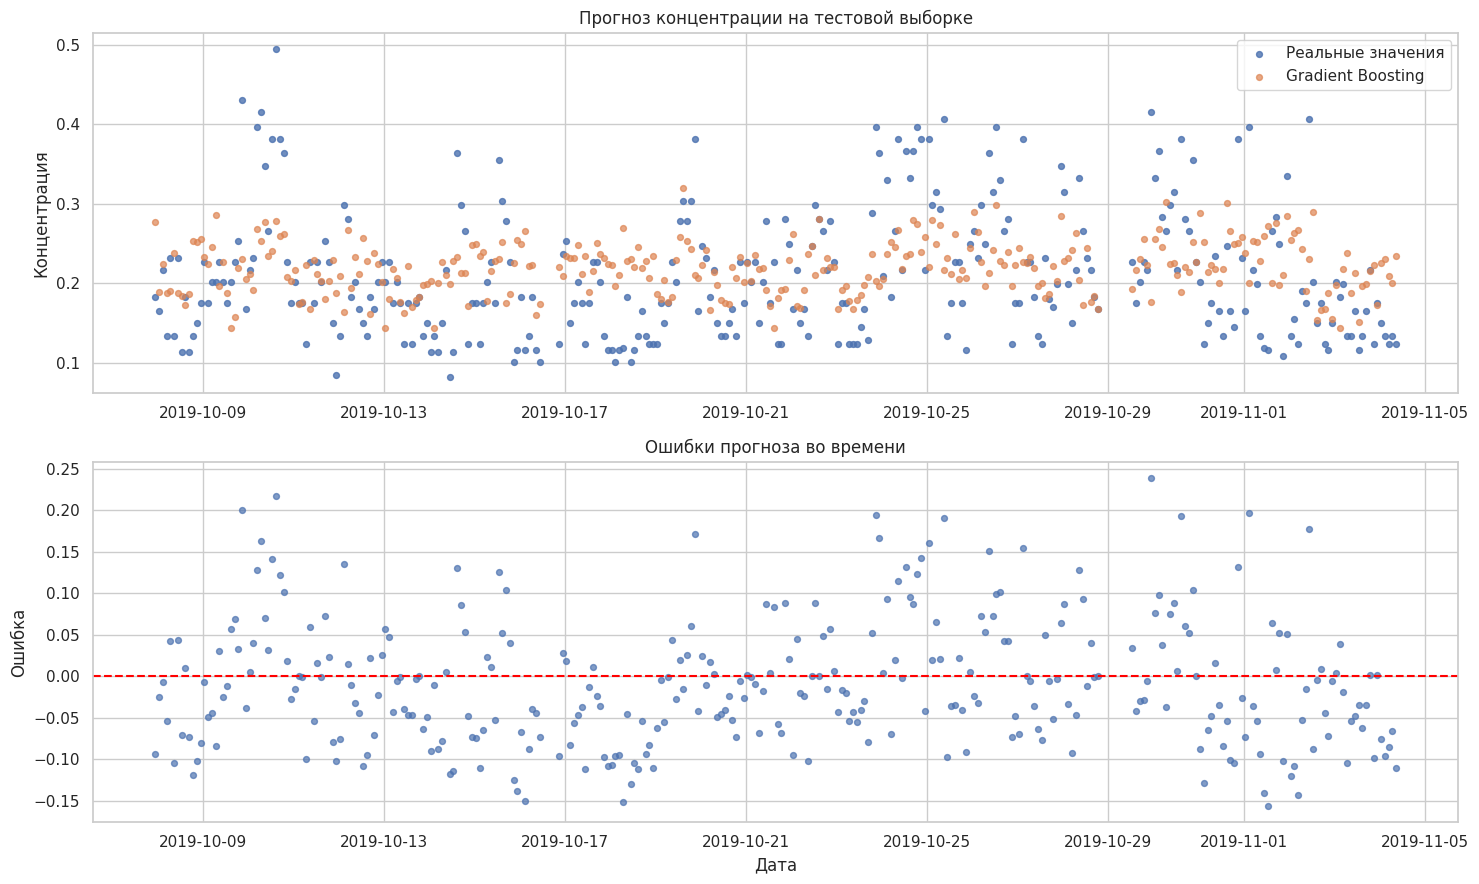

In [38]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9))

# Реальные значения и прогнозы
axes[0].scatter(
    y_test.index, y_test,
    s=18, label="Реальные значения", alpha=0.8
)

axes[0].scatter(
    y_test.index, test_pred,
    s=18, label="Gradient Boosting", alpha=0.7
)

axes[0].set_title("Прогноз концентрации на тестовой выборке")
axes[0].set_ylabel("Концентрация")
axes[0].legend()

# Ошибки прогнозирования
test_residuals = y_test.to_numpy() - test_pred

axes[1].scatter(
    y_test.index, test_residuals,
    s=18, alpha=0.7
)

axes[1].axhline(
    0, color="red", linestyle="--"
)

axes[1].set_title("Ошибки прогноза во времени")
axes[1].set_xlabel("Дата")
axes[1].set_ylabel("Ошибка")

plt.tight_layout()
plt.show()

### 2.4. Итоговые выводы по лабораторной работе

В ходе лабораторной работы разработан прототип виртуального датчика для оценки концентрации выходного продукта в процессе обжига на основании показаний технологической телеметрии.

**1. Анализ исходных данных**

Были исследованы 16 телеметрических показателей, поступающих с различной периодичностью, и нерегулярные лабораторные измерения концентрации.

Выполнены анализ пропусков, дубликатов, выбросов, временных зависимостей и корреляций. Проведена синхронизация лабораторных измерений с телеметрией с учётом предполагаемой задержки получения результата 15 минут.

**2. Инжиниринг признаков**

Сформировано 112 признаков, включающих исходные показания, временные лаги, скользящие статистики, скорости изменения параметров, давность измерений и календарные характеристики.

Это позволило учитывать не только текущее состояние оборудования, но и динамику технологического процесса.

**3. Построение моделей**

Были обучены и сравнены три модели регрессии: Ridge, Random Forest и Gradient Boosting.

Лучшей моделью по MAE на валидационной выборке стала Gradient Boosting (MAE = 0.0633). Random Forest показал более высокую точность определения направления изменений концентрации — 59.16%.

**4. Оценка качества**

На независимой тестовой выборке Gradient Boosting достигла следующих результатов:

- MAE = 0.0615;
- RMSE = 0.0770;
- MAPE = 33.76%;
- WAPE = 29.35%;
- Directional Accuracy = 56.19%.

По сравнению с базовым прогнозом медианной концентрации MAE уменьшилась приблизительно на 19.9%.

Анализ остатков показал отсутствие статистически значимого отклонения от нормальности, но выявил автокорреляцию и гетероскедастичность.

**5. Интерпретация**

Согласно Permutation Importance наиболее значимыми оказались `telemetry_12`, `telemetry_15` и `telemetry_11`. Также модель использует лаги и скользящие статистики, что подтверждает полезность учёта временной динамики.

При этом модель склонна сглаживать резкие изменения концентрации и недостаточно точно воспроизводит экстремальные значения.

**6. Ограничения и дальнейшее развитие**

Разработанная модель обладает следующими ограничениями:

- сравнительно небольшое количество размеченных лабораторных наблюдений;
- отсутствие физических описаний датчиков;
- неопределённость фактической временной привязки лабораторных измерений;
- недостаточная точность определения направления изменения концентрации;
- снижение качества прогнозирования при резких изменениях технологического режима.

Перспективными направлениями развития являются расширение обучающей выборки, уточнение временной синхронизации, дополнительный подбор гиперпараметров и применение специализированных методов моделирования временных рядов.

**Итоговый вывод**

Разработанная модель демонстрирует улучшение качества прогнозирования концентрации относительно базового подхода и может рассматриваться как прототип виртуального датчика.

Однако текущие ошибки прогнозирования не позволяют считать модель готовой к самостоятельному управлению промышленным процессом. Для практического внедрения необходимы дополнительные испытания, проверка на новых производственных данных и определение допустимых технологических погрешностей.